In [115]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [116]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import ijson
import seaborn as sns
from data_processing_utils import *

In [119]:
# I-24 MOTION Inception unique identifiers (all post-processed runs start 06:00 CST)
I24_IDENTIFIERS = {
    "11_21": "637b023440527bf2daa5932f__post1",
    "11_22": "637c399add50d54aa5af0cf4__post2",
    "11_23": "637d8ea678f0cb97981425dd__post3",
    "11_24": "637f0d5f78f0cb97981425de__post4",
    "11_25": "6380728cdd50d54aa5af0cf5__post5",
    "11_28": "638450a3dd50d54aa5af0cf6__post8",
    "11_29": "63858a2cfb3ff533c12df166__post9",
    "11_30": "6386d89efb3ff533c12df167__post10",
    "12_01": "63882be478f0cb97981425df__post11",
    "12_02": "63898d48d430891009401330__post12",
}

# Only these need to change
DATE = "12_02"  # month_day, must be a key above
NUM_HOURS = 4
START_TIME_CST = "06:00"  # start of the window to load, local time

DIRECTION = "west"
I24_DATA_DIR = f"raw_i24_data/"
input_filename = f"{I24_IDENTIFIERS[DATE]}.json"

# Trajectory timestamps are UTC, so convert the local start time to UTC
month, day = DATE.split("_")
min_t = (
    pd.Timestamp(f"2022-{month}-{day} {START_TIME_CST}")
    .tz_localize("US/Central")
    .tz_convert("UTC")
    .tz_localize(None)
)

DATA_DIR = "data/"
FILE_NAME = f"{DIRECTION}bound_trajectories_{NUM_HOURS}_hr_df.csv"
FILE_PATH = DATA_DIR + FILE_NAME

SAVE_PATH = f"data/i24_{NUM_HOURS}hrs/i24_{DATE}"
os.makedirs(SAVE_PATH, exist_ok=True)
print(f"Loading {input_filename}, from {min_t} UTC for {NUM_HOURS} hr -> {SAVE_PATH}")

Loading 63898d48d430891009401330__post12.json, from 2022-12-02 12:00:00 UTC for 4 hr -> data/i24_4hrs/i24_12_02


In [120]:
file_path = os.path.join(I24_DATA_DIR, input_filename)
westbound_trajectories_1_hr_df = load_trajectories(
    file_path, pd.Timedelta(hours=NUM_HOURS), min_t, direction_str=DIRECTION
)
# westbound_trajectories_1_hr_df.to_csv(FILE_PATH)

Loaded 471794 westbound trajectories.
['trajectory_id', 'timestamp', 'x_position', 'y_position']
           trajectory_id                     timestamp    x_position  \
0                      0 2022-12-02 12:00:00.100000143  96057.390625   
1                      0 2022-12-02 12:00:00.140000343  96055.843750   
2                      0 2022-12-02 12:00:00.180000305  96054.312500   
3                      0 2022-12-02 12:00:00.220000267  96052.781250   
4                      0 2022-12-02 12:00:00.260000467  96051.242188   
...                  ...                           ...           ...   
160715607         471793 2022-12-02 14:20:14.740000010  98985.421875   
160715608         471793 2022-12-02 14:20:14.780000210  98984.828125   
160715609         471793 2022-12-02 14:20:14.820000172  98984.226562   
160715610         471793 2022-12-02 14:20:14.860000372  98983.632812   
160715611         471793 2022-12-02 14:20:14.900000095  98983.039062   

           y_position  
0           16

In [121]:
# load CSV
# westbound_trajectories_1_hr_df = pd.read_csv(FILE_PATH)

In [122]:
westbound_trajectories_1_hr_df["timestamp"] = pd.to_datetime(
    westbound_trajectories_1_hr_df["timestamp"]
)

In [123]:
from scipy.interpolate import griddata

def fill_2d(a, bad, space_scale=5.0):
    """Fill bad cells by linear interpolation from good cells nearby in time and space.
    space_scale: one segment counts as this many 10 s steps (larger = lean more on the same segment over time)."""
    t, s = np.indices(a.shape)
    pts_good = np.c_[t[~bad], s[~bad] * space_scale]
    pts_bad = np.c_[t[bad], s[bad] * space_scale]
    vals = griddata(pts_good, a[~bad], pts_bad, method="linear")
    miss = np.isnan(vals)  # bad cells at the edges or corners: use the nearest good cell
    if miss.any():
        vals[miss] = griddata(pts_good, a[~bad], pts_bad[miss], method="nearest")
    out = a.astype(float).copy()
    out[bad] = vals
    return out

xmax 101066.805
x_min 94629.43
Filled 667 cells
flow shape (time, space): (1440, 16)


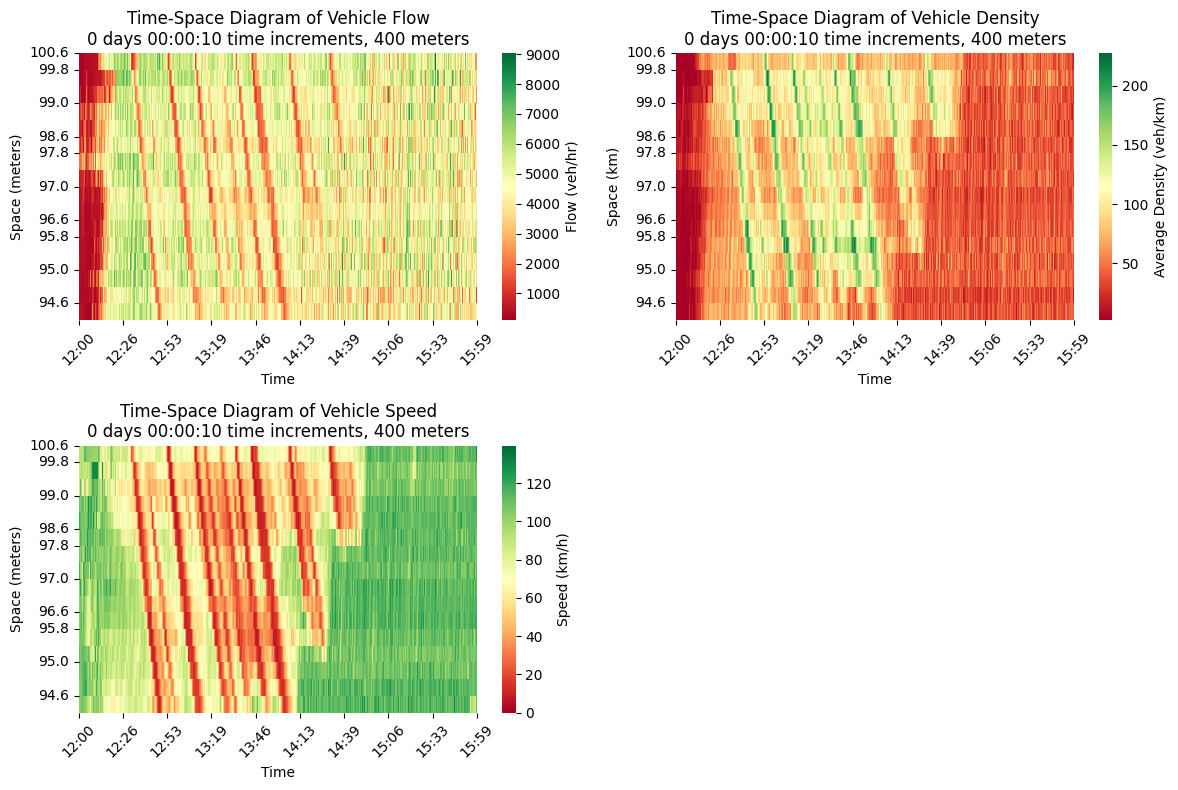

In [124]:
import importlib, data_processing_utils
importlib.reload(data_processing_utils)
from data_processing_utils import plot_matrices

TIME_INT = 10  # seconds
DISTANCE = 400  # meters

flow, density = get_flow_density_matrix(
    westbound_trajectories_1_hr_df,
    time_interval=pd.Timedelta(seconds=TIME_INT),
    space_interval=DISTANCE,
    output_filename=f"{TIME_INT}sec_{DISTANCE}_m_flow_speed_{NUM_HOURS}hr.csv",
    start_time=min_t,
    end_time=min_t + pd.Timedelta(hours=NUM_HOURS),
)
t_min, t_max = (
    westbound_trajectories_1_hr_df["timestamp"].min(),
    westbound_trajectories_1_hr_df["timestamp"].max(),
)
x_min, x_max = (
    westbound_trajectories_1_hr_df["x_position"].min(),
    westbound_trajectories_1_hr_df["x_position"].max(),
)


# Accounting for cameras that were down/damaged/obscured + flipping for direction
flow = flow[:, :-1]
flow = np.flip(flow, axis=1)
flow[:, 6] = (flow[:, 5] + flow[:, 7]) / 2
# flow[:, 10] = (flow[:, 9] + flow[:, 11]) / 2
density = density[:, :-1]
density = np.flip(density, axis=1)
density[:, 6] = (density[:, 5] + density[:, 7]) / 2
# density[:, 10] = (density[:, 9] + density[:, 11]) / 2
with np.errstate(invalid="ignore", divide="ignore"):
    velocity_arr = flow / density
# Cells with no vehicles have undefined speed: fill from the nearest time steps in the same cell
MIN_DENSITY = 2.0   # veh/km (all lanes): below this, the cell is unreliable
V_MAX = 140.0       # km/h: faster means bad data in the cell

with np.errstate(invalid="ignore", divide="ignore"):
    velocity_arr = flow / density
bad = (density < MIN_DENSITY) | ~np.isfinite(velocity_arr) | (velocity_arr > V_MAX)

# Treat bad cells as missing in both flow and density, fill each from nearby time steps,
# then recompute speed so q = rho * v holds everywhere.
flow[bad] = np.nan
density[bad] = np.nan
flow = fill_2d(flow, bad)
density = fill_2d(density, bad)
velocity_arr = flow / density
print(f"Filled {bad.sum()} cells")

print("flow shape (time, space):", flow.shape)

np.save(f"{SAVE_PATH}/q_hat.npy", flow)
np.save(f"{SAVE_PATH}/rho_hat.npy", density)
np.save(f"{SAVE_PATH}/v_hat.npy", velocity_arr)

plot_matrices(
    np.flip(flow, axis=1),
    np.flip(density, axis=1),
    np.flip(velocity_arr, axis=1),
    pd.Timedelta(seconds=TIME_INT),
    DISTANCE,
    t_min,
    t_max,
    x_min,
    x_max,
)

In [125]:
for name, arr in [("q_hat", flow), ("rho_hat", density), ("v_hat", velocity_arr)]:
    assert np.isfinite(arr).all(), f"{name} has {np.size(arr) - np.isfinite(arr).sum()} NaN/inf values"

In [126]:
# Copy the lane and ramp mappings from the 1-hour data folder for this day.
# These only depend on the road layout (one value per space cell), not on time.
MAPPING_SOURCE = f"data/i24/i24_{DATE}"
for name in ["lane_mapping", "on_ramp_mapping", "off_ramp_mapping"]:
    mapping = np.load(f"{MAPPING_SOURCE}/{name}.npy", allow_pickle=True)
    assert mapping.shape[0] == flow.shape[1], (
        f"{name} has {mapping.shape[0]} cells but flow has {flow.shape[1]}"
    )
    np.save(f"{SAVE_PATH}/{name}.npy", mapping)
    print(f"Saved {name} {mapping.shape} -> {SAVE_PATH}/{name}.npy")

Saved lane_mapping (16,) -> data/i24_4hrs/i24_12_02/lane_mapping.npy
Saved on_ramp_mapping (16,) -> data/i24_4hrs/i24_12_02/on_ramp_mapping.npy
Saved off_ramp_mapping (16,) -> data/i24_4hrs/i24_12_02/off_ramp_mapping.npy
